In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pyarrow.parquet as pq
from torch.utils.data import DataLoader, IterableDataset
import math
import random
from utils.models import *
from utils.train_test import *
from utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec
torch.set_float32_matmul_precision('high')
# --- 1. Configurações e Imports dos Modelos ---
# (Certifique-se de que as classes dos modelos estejam definidas ou importadas aqui)
# from models import convnext_tiny_1d, resnet50_1d 

#DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#NUM_CLASSES = 13683
#MAX_LEN = 512
#NUM_FEATURES = 4
#BATCH_SIZE = 2048 # Pode ser maior no teste (apenas inferência)
#base_type_data = "species"
# Caminhos dos seus Melhores Modelos (Atualize estes caminhos!)
PATH_RESNET = f"../cnn_kraken_{base_type_data}/checkpoints/best_resnet_classifier__fast_phase4.pt" # Exemplo: seu melhor checkpoint da ResNet
PATH_CONVNEXT_zero = f"./checkpoint_{base_type_data}_conv_zero/best_convnext_phase3_restarts_v2.pt" # Seu atual campeão
PATH_CONVNEXT_transfer =  f"./checkpoint_transfer_{base_type_data}_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine =  f"./checkpoint_transfer_{base_type_data}_conv/finetune_noise_7.pt"
PATH_RESNET_fine = f"./checkpoint_finetune_resnet/finetune_noise_14.pt"






/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/__init__.py:1624: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [2]:
from utils.dna_dataset_2 import DaskCuDFIntegerDataset

# Parâmetros de configuração
NUM_CLASSES = 13683
#NUM_CLASSES = 2702
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 8192
#BATCH_SIZE = 496
NUM_WORKERS = 0
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'
PREFETCH_FACTOR = None
base_type_data = "species"
#base_type_data = "genus"
# Get Parquet file paths for the splits
fs = fsspec.filesystem('file')
base_output_directory = f"./processed_kraken_{base_type_data}_splited_parquet"
#base_output_directory = "./synthetic_splited_dataset"
train_dir = os.path.join(base_output_directory, "train")
test_dir = os.path.join(base_output_directory, "test")
val_dir = os.path.join(base_output_directory, "validation")
train_file_paths = fs.glob(os.path.join(train_dir, '*.parquet'))
test_file_paths = fs.glob(os.path.join(test_dir, '*.parquet'))
val_file_paths = fs.glob(os.path.join(val_dir, '*.parquet'))
print(f"Found {len(train_file_paths)} train files, {len(test_file_paths)} test files, {len(val_file_paths)} validation files.")


print(f"Configurando DataLoader com {NUM_WORKERS} workers e prefetch de {PREFETCH_FACTOR} lotes.")


test_dataset = DaskCuDFIntegerDataset(
    test_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)



test_loader = DataLoader(
    test_dataset,
    num_workers=NUM_WORKERS,
    pin_memory=False,
    prefetch_factor=PREFETCH_FACTOR,
    batch_size=None 
)

print("PyTorch DataLoaders criados.")



Found 256 train files, 256 test files, 256 validation files.
Configurando DataLoader com 0 workers e prefetch de None lotes.
PyTorch DataLoaders criados.


In [3]:
from utils.models import *


In [4]:
models = [
    {
        "model_name":"ConvNext finetuned",
        "path":PATH_CONVNEXT_fine,
        "type":"CONVNEXT_FINE"
        
    },
    {
        "model_name":"ConvNext from scratch",
        "path":PATH_CONVNEXT_zero,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ConvNext transfer from genus",
        "path":PATH_CONVNEXT_transfer,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ResNet50",
        "path":PATH_RESNET,
        "type":"RESNET"
    },
    {
        "model_name":"ResNet50_finetuned",
        "path":PATH_RESNET_fine,
        "type":"RESNET_FINE"
    },
]

In [5]:
def load_model(model_dict):
    # 1. Instanciação do Modelo Base
    if "CONVNEXT" in model_dict["type"]:
        dropout = 0.7 if model_dict["type"] == "CONVNEXT_FINE" else 0.5
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=dropout)
    elif "RESNET" in model_dict["type"]:
        model = resnet50_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=0.5)
    else:
        raise ValueError(f"Tipo de modelo desconhecido: {model_dict['type']}")

    # 2. Carregamento dos Pesos no modelo 'bruto'
    # Usar map_location garante que os pesos caiam no lugar certo desde o início
    try:
        print(f"Carregando pesos de: {model_dict['path']}")
        checkpoint = torch.load(model_dict["path"], map_location=DEVICE)
        
        # Extrai o dicionário de estados (suporta formatos simples ou com metadados de treino)
        state_dict = checkpoint["model_state_dict"] if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint else checkpoint
        
        # Limpa o prefixo '_orig_mod.' caso o checkpoint tenha sido salvo de um modelo já compilado
        new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
        
        model.load_state_dict(new_state_dict)
        print(f"Sucesso! Pesos carregados para {model_dict['model_name']}.")
    except Exception as e:
        raise RuntimeError(
            f"Falha ao carregar checkpoint de "
            f"{model_dict['model_name']}: {e}"
        ) from e

    # 3. Preparação para Inferência
    model.to(DEVICE)
    model.eval() # Essencial para congelar BatchNorm e Dropout antes da compilação

    # 4. Compilação (O ÚLTIMO PASSO)
    # Compilar apenas após o modelo estar com os pesos finais e no device correto
    print(f"Compilando modelo {model_dict['model_name']}...")
    model = torch.compile(model)
    
    return model

In [6]:
import torch
import numpy as np
import pandas as pd
from umap import UMAP
import plotly.express as px
#from cuml.manifold import UMAP as GPU_UMAP

def extract_latent_features(model, dataloader, device='cuda'):
    model.eval()

    latent_data = []
    labels_list = []

    target_model = (
        model._orig_mod
        if hasattr(model, "_orig_mod")
        else model
    )

    # Captura exatamente o vetor fornecido ao classifier
    def pre_hook_fn(module, inputs):
        x = inputs[0]
        latent_data.append(
            x.detach().cpu().numpy()
        )

    handle = target_model.fc.register_forward_pre_hook(
        pre_hook_fn
    )

    try:
        with torch.inference_mode():
            for inputs, labels in tqdm(
                dataloader,
                desc="Extraindo Espaço Latente"
            ):
                inputs = inputs.to(device)

                _ = model(inputs)

                labels_list.append(
                    labels.cpu().numpy()
                )

    finally:
        handle.remove()

    return (
        np.concatenate(latent_data, axis=0),
        np.concatenate(labels_list, axis=0)
    )

In [7]:
import os
import pandas as pd
import numpy as np
import torch

# Crie a pasta de resultados se não existir
output_dir = 'results_latent'
os.makedirs(output_dir, exist_ok=True)

for model_dict in models:
    name_clean = model_dict['model_name'].replace(" ", "_").lower()
    file_path_umap = os.path.join(output_dir, f"umap_{name_clean}.parquet")
    file_path_features = os.path.join(output_dir, f"features_{name_clean}.parquet")
    
    print(f"\n🔍 Verificando resultados para: {model_dict['model_name']}")
    
    # Verifica se ambos os arquivos já existem no disco
    if os.path.exists(file_path_umap) and os.path.exists(file_path_features):
        print(f"♻️  Arquivos encontrados! Carregando dados salvos...")
        
        # Load UMAP coordinates -- visualization only
        df_latent = pd.read_parquet(file_path_umap)
        
        # Load ORIGINAL high-dimensional latent features
        df_features = pd.read_parquet(file_path_features)
        
        # Original latent space used for quantitative analysis
        model_dict['features'] = df_features.values
        
        # Labels
        model_dict['labels'] = df_latent['species_id'].values
        
        # UMAP embedding used ONLY for visualization
        model_dict['umap'] = df_latent[['umap_1', 'umap_2']].values
        
        # Opcional: Carregar features originais se necessário para a sessão atual
        # df_features = pd.read_parquet(file_path_features)
        
    else:
        print(f"⚙️  Dados não encontrados. Iniciando processamento pesado...")
        
        # 0. Carregar e Extrair (Consome VRAM na Blackwell)[cite: 1, 3]
        model = load_model(model_dict)
        # 1. Extract original high-dimensional latent features
        features, labels = extract_latent_features(model, test_loader)
        
        # Store ORIGINAL latent space
        model_dict['features'] = features
        model_dict['labels'] = labels
        
        # 2. UMAP is ONLY for visualization
        reducer = UMAP(
            n_neighbors=15,
            min_dist=0.1,
            n_components=2,
            metric='cosine',
            random_state=42
        )
        
        umap_embedding = reducer.fit_transform(features)
        
        model_dict['umap'] = umap_embedding
        
        df_latent = pd.DataFrame({
            'umap_1': umap_embedding[:, 0],
            'umap_2': umap_embedding[:, 1],
            'species_id': labels
        })
        
        df_features = pd.DataFrame(features)
        
        df_latent.to_parquet(file_path_umap, index=False)
        df_features.to_parquet(file_path_features, index=False)
        
        print(f"✅ Processamento concluído e salvo em: {output_dir}")
        
        # Limpeza agressiva de memória para o próximo modelo
        del model
        torch.cuda.empty_cache()
    
    print(f"--- Fim da etapa para {model_dict['model_name']} ---")


🔍 Verificando resultados para: ConvNext finetuned
♻️  Arquivos encontrados! Carregando dados salvos...
--- Fim da etapa para ConvNext finetuned ---

🔍 Verificando resultados para: ConvNext from scratch
♻️  Arquivos encontrados! Carregando dados salvos...
--- Fim da etapa para ConvNext from scratch ---

🔍 Verificando resultados para: ConvNext transfer from genus
♻️  Arquivos encontrados! Carregando dados salvos...
--- Fim da etapa para ConvNext transfer from genus ---

🔍 Verificando resultados para: ResNet50
♻️  Arquivos encontrados! Carregando dados salvos...
--- Fim da etapa para ResNet50 ---

🔍 Verificando resultados para: ResNet50_finetuned
♻️  Arquivos encontrados! Carregando dados salvos...
--- Fim da etapa para ResNet50_finetuned ---


In [8]:
import os
import pandas as pd
import plotly.express as px
from IPython.display import Image, display

def plot_latent_space(embedding, labels, taxonomy_df, model_name, output_dir="latent_plots", taxonomic_level="Genus"):
    """
    Gera o scatter plot do espaço latente via Plotly,
    exporta em HTML (com legenda) e PNG (sem legenda), 
    exibindo a imagem estática limpa no notebook.
    """
    # Cria o diretório de destino se não existir
    os.makedirs(output_dir, exist_ok=True)
    
    # Nomes limpos para os arquivos baseado no modelo e no nível taxonômico
    name_clean = model_name.replace(" ", "_").lower()
    tax_clean = taxonomic_level.replace(" ", "_").lower()

    print(f"🧬 Mapeando linearmente {len(labels)} amostras para o nível '{taxonomic_level}'...")
    
    # A Espécie sempre fica no hover (informação fina), e a cor é definida pelo parâmetro
    names = [taxonomy_df.loc[l, 'species'] for l in labels]
    
    # Extrai o rótulo taxonômico dinâmico. Se a coluna não existir, evita quebra.
    if taxonomic_level in taxonomy_df.columns:
        tax_labels = [taxonomy_df.loc[l, taxonomic_level] for l in labels]
    else:
        raise ValueError(f"❌ A coluna '{taxonomic_level}' não existe no taxonomy_df. Verifique o nome exato.")

    # Formata o nome da coluna para ficar elegante no gráfico (ex: "order" vira "Order")
    col_color_name = taxonomic_level.capitalize()

    df_plot = pd.DataFrame({
        'UMAP 1': embedding[:, 0],
        'UMAP 2': embedding[:, 1],
        'Espécie': names,
        col_color_name: tax_labels
    })

    print(f"📊 Processando topologia UMAP para: {model_name}...")
    
    fig = px.scatter(
        df_plot,
        x='UMAP 1',
        y='UMAP 2',
        color=col_color_name,
        hover_data=['Espécie'],
        title=f"{model_name} Latent Space Topology - UMAP ({col_color_name})"
    )

    fig.update_traces(marker=dict(size=5, opacity=0.7))
    
    # 🌐 ==============================================================================
    # 1. EXPORTAÇÃO EM HTML (COM LEGENDA)
    # ==============================================================================
    path_html = os.path.join(output_dir, f"ICTV_latent_space_{name_clean}_{tax_clean}.html")
    fig.write_html(path_html)
    print(f"🌐 HTML interativo salvo em disco (COM legenda): {path_html}")
    
    # 🛑 OCULTA A LEGENDA NO GRÁFICO (Para não achatar o PNG)
    fig.update_layout(showlegend=False)

    # 💾 ==============================================================================
    # 2. EXPORTAÇÃO EM PNG (SEM LEGENDA)
    # ==============================================================================
    path_png = os.path.join(output_dir, f"ICTV_latent_space_{name_clean}_{tax_clean}.png")
    fig.write_image(path_png, format="png", scale=3, width=1000, height=700)
    print(f"💾 Imagem estática salva (SEM legenda): {path_png}")
    
    # 🖼️ ==============================================================================
    # 3. EXIBIÇÃO ESTÁTICA NO JUPYTER (SEM LEGENDA)
    # ==============================================================================
    print(f"Exibindo prévia estática colorida por {col_color_name}...")
    display(Image(filename=path_png, width=800)) 
    
    # Libera a memória instantaneamente
    fig = None

In [9]:
taxonomy_df = pd.read_parquet("./main_taxonomy_hybrid_CLEANSED.parquet")
taxonomy_df.head(5)

,species,id,species_clean,species_ictv,ictv_status,species_validated_name,Realm,Subrealm,Kingdom,Subkingdom,...,Class,Subclass,Order,Suborder,Family,Subfamily,Genus,Subgenus,taxonomy_source,full_lineage
0,Alphafusarivirus rutstroemiae,1,alphafusarivirus rutstroemiae,alphafusarivirus rutstroemiae,Homologado (ICTV Direct),Alphafusarivirus rutstroemiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
1,Alphafusarivirus macrophominae,2,alphafusarivirus macrophominae,alphafusarivirus macrophominae,Homologado (ICTV Direct),Alphafusarivirus macrophominae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
2,Alphafusarivirus ioaponiae,3,alphafusarivirus ioaponiae,alphafusarivirus ioaponiae,Homologado (ICTV Direct),Alphafusarivirus ioaponiae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
3,Alphafusarivirus auriculariae,4,alphafusarivirus auriculariae,alphafusarivirus auriculariae,Homologado (ICTV Direct),Alphafusarivirus auriculariae,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...
4,Alphafusarivirus penicilli,5,alphafusarivirus penicilli,alphafusarivirus penicilli,Homologado (ICTV Direct),Alphafusarivirus penicilli,Riboviria,NaN,Orthornavirae,NaN,...,Stelpaviricetes,NaN,Hypofuvirales,None,Fusariviridae,None,Alphafusarivirus,None,ICTV Master,Riboviria / Orthornavirae / Pisuviricota / Ste...


🧬 Mapeando linearmente 1706270 amostras para o nível 'Genus'...
📊 Processando topologia UMAP para: ConvNext finetuned...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_finetuned_genus.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_finetuned_genus.png
Exibindo prévia estática colorida por Genus...


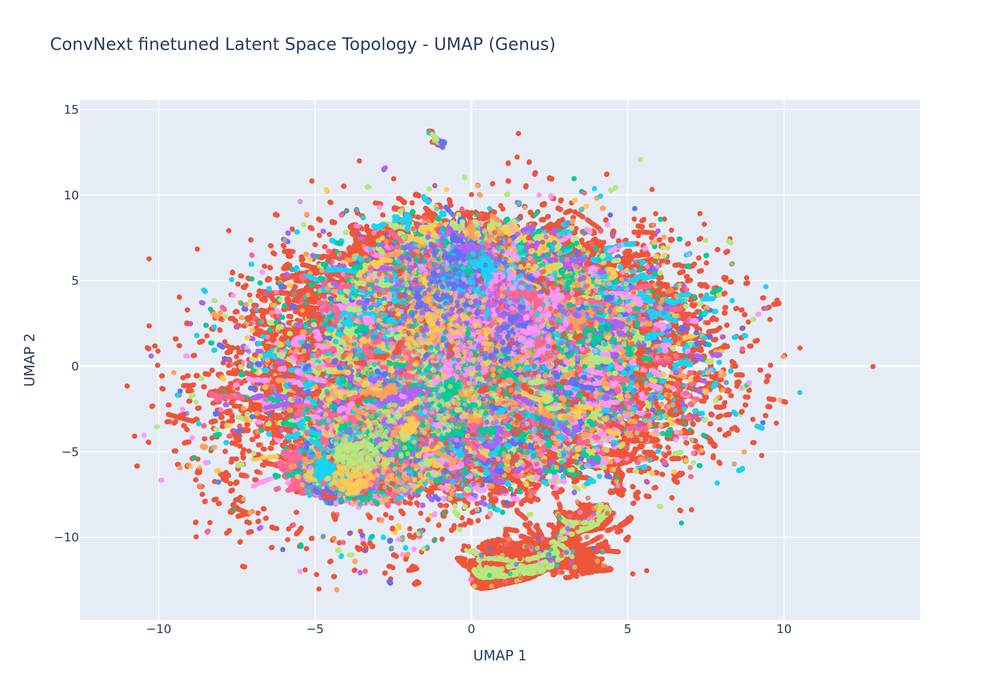

🧬 Mapeando linearmente 1706270 amostras para o nível 'Genus'...
📊 Processando topologia UMAP para: ConvNext from scratch...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_from_scratch_genus.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_from_scratch_genus.png
Exibindo prévia estática colorida por Genus...


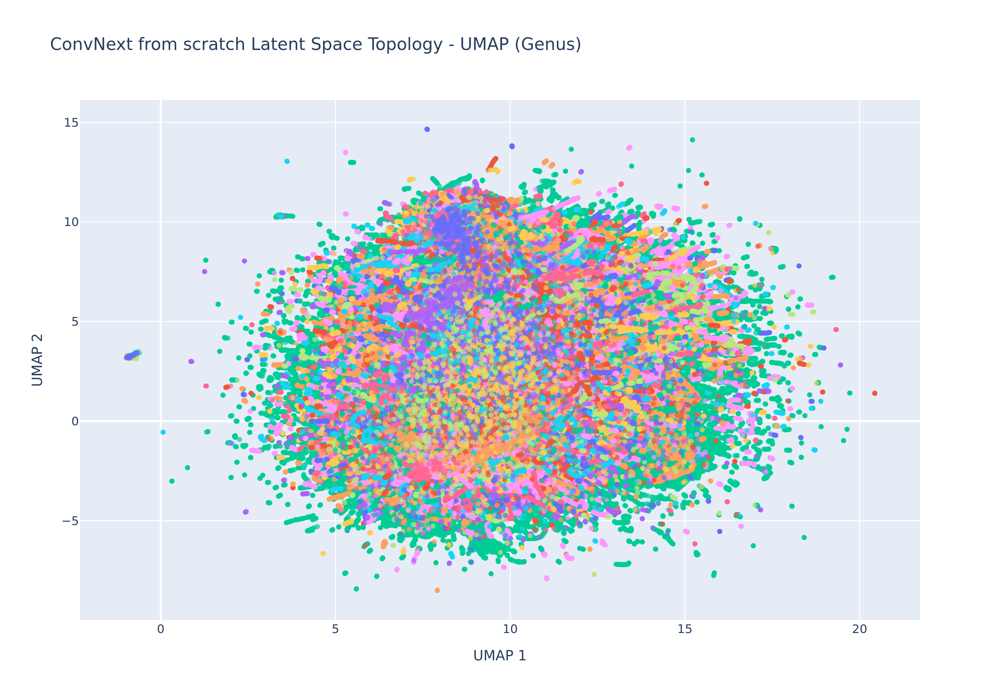

🧬 Mapeando linearmente 1706270 amostras para o nível 'Genus'...
📊 Processando topologia UMAP para: ConvNext transfer from genus...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_transfer_from_genus_genus.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_transfer_from_genus_genus.png
Exibindo prévia estática colorida por Genus...


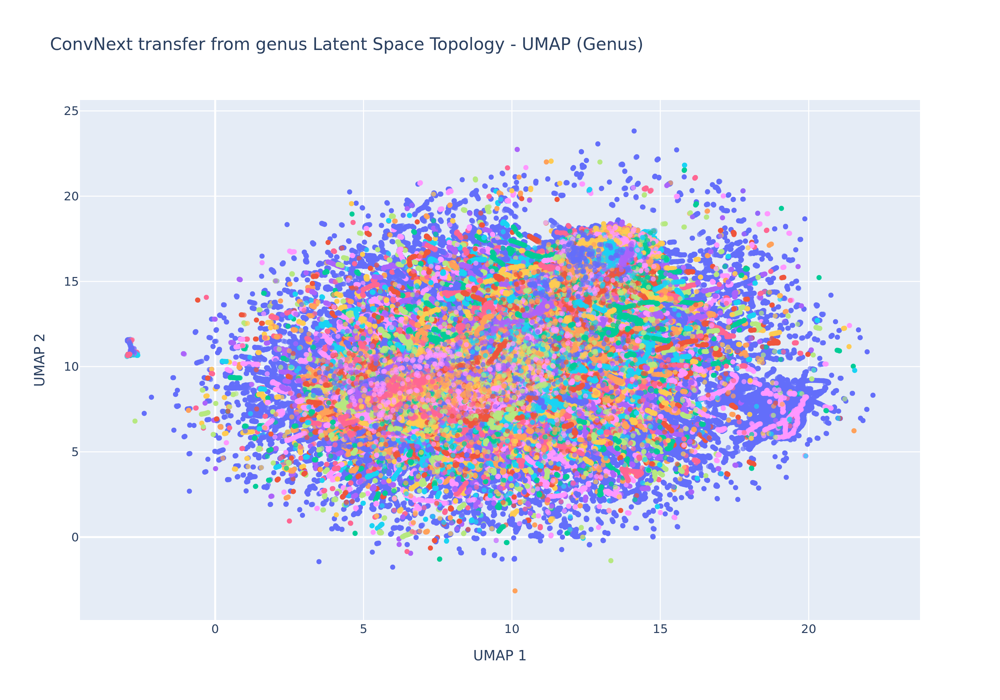

🧬 Mapeando linearmente 1706270 amostras para o nível 'Genus'...
📊 Processando topologia UMAP para: ResNet50...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_resnet50_genus.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_resnet50_genus.png
Exibindo prévia estática colorida por Genus...


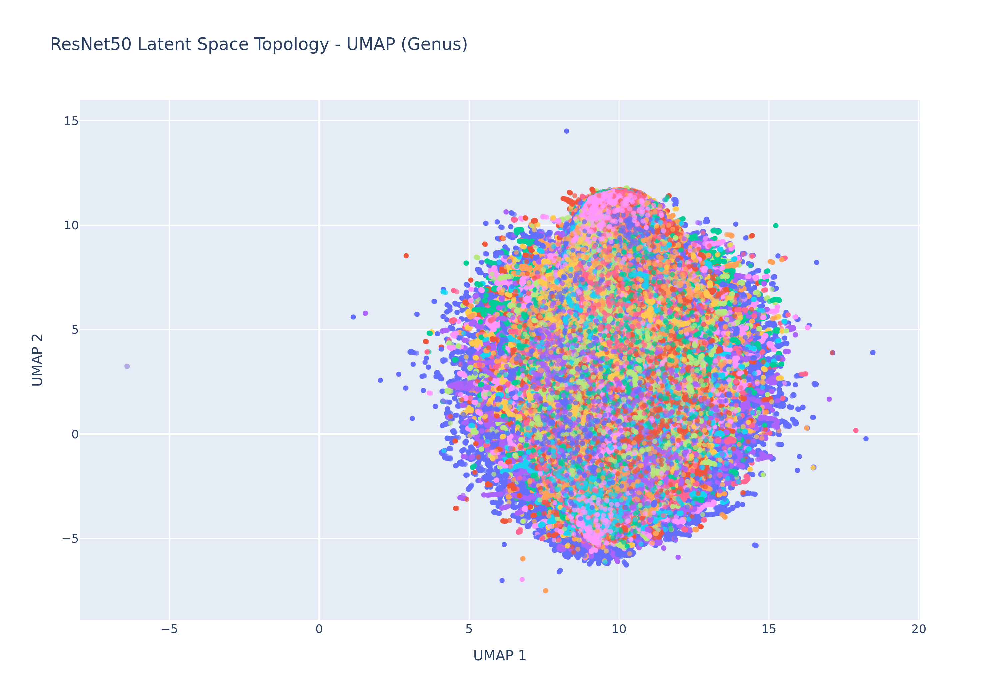

🧬 Mapeando linearmente 1706270 amostras para o nível 'Genus'...
📊 Processando topologia UMAP para: ResNet50_finetuned...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_resnet50_finetuned_genus.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_resnet50_finetuned_genus.png
Exibindo prévia estática colorida por Genus...


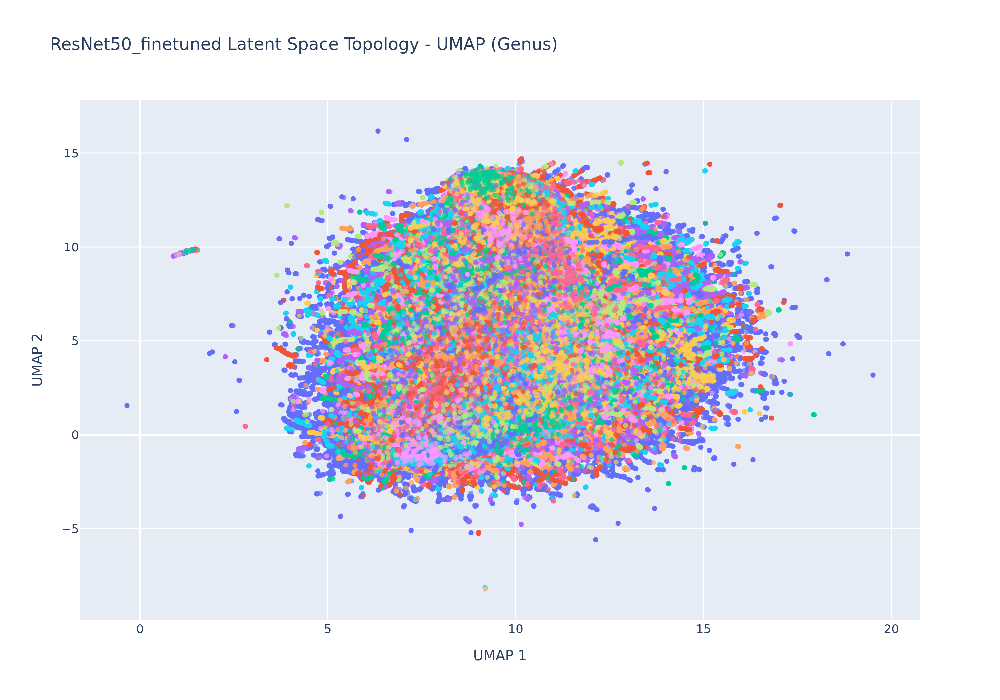

In [10]:
for model_dict in models:
    plot_latent_space(model_dict['umap'], model_dict['labels'], taxonomy_df, model_dict['model_name'])
    

🧬 Mapeando linearmente 1706270 amostras para o nível 'Order'...
📊 Processando topologia UMAP para: ConvNext finetuned...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_finetuned_order.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_finetuned_order.png
Exibindo prévia estática colorida por Order...


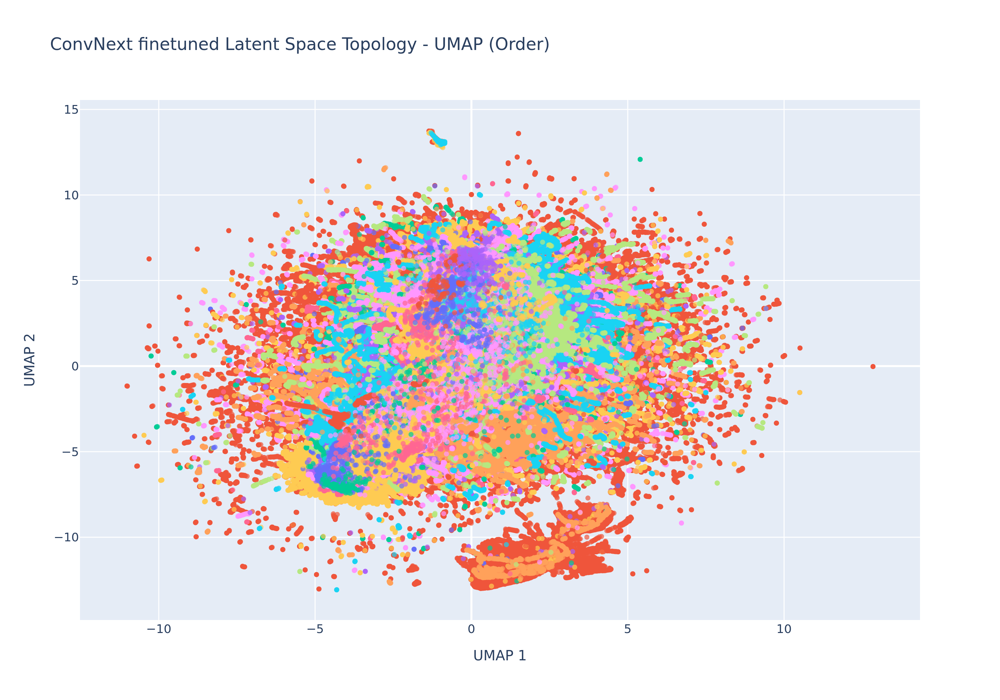

🧬 Mapeando linearmente 1706270 amostras para o nível 'Order'...
📊 Processando topologia UMAP para: ConvNext from scratch...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_from_scratch_order.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_from_scratch_order.png
Exibindo prévia estática colorida por Order...


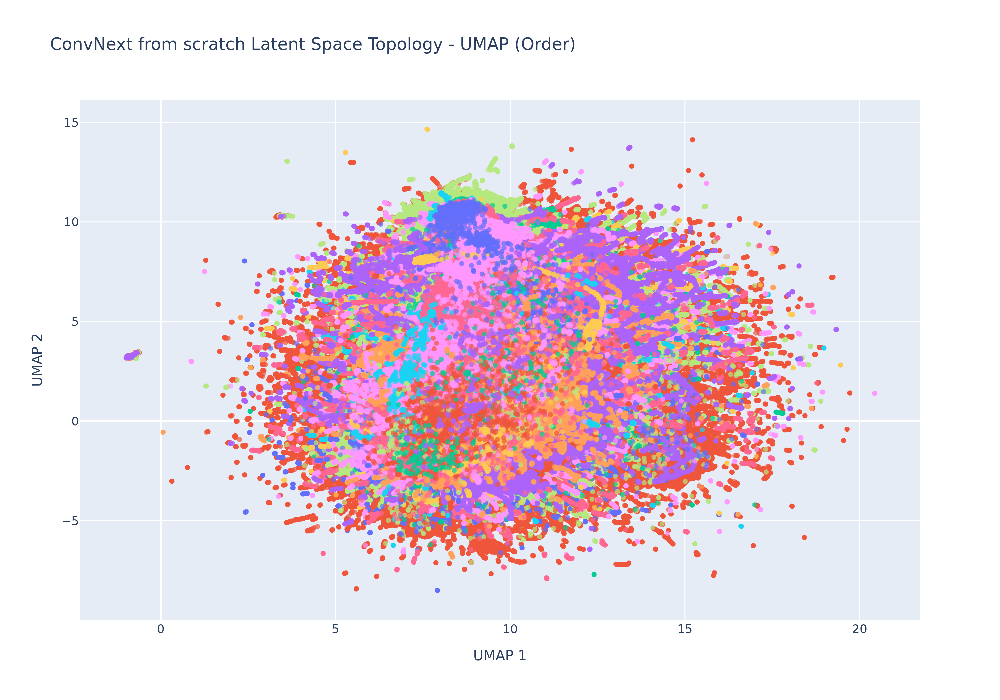

🧬 Mapeando linearmente 1706270 amostras para o nível 'Order'...
📊 Processando topologia UMAP para: ConvNext transfer from genus...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_convnext_transfer_from_genus_order.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_convnext_transfer_from_genus_order.png
Exibindo prévia estática colorida por Order...


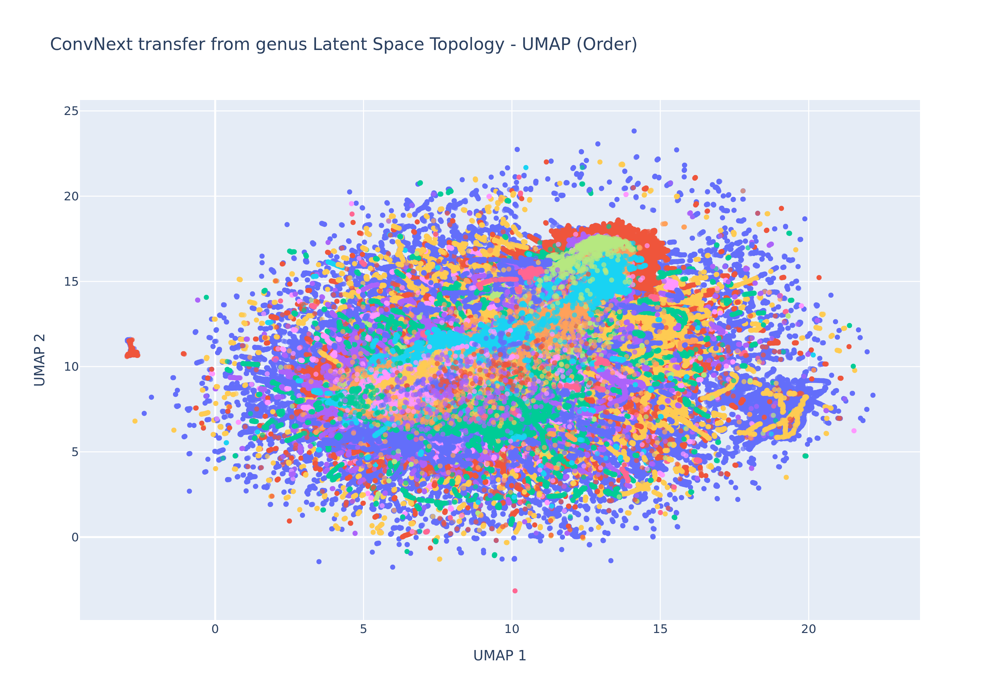

🧬 Mapeando linearmente 1706270 amostras para o nível 'Order'...
📊 Processando topologia UMAP para: ResNet50...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_resnet50_order.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_resnet50_order.png
Exibindo prévia estática colorida por Order...


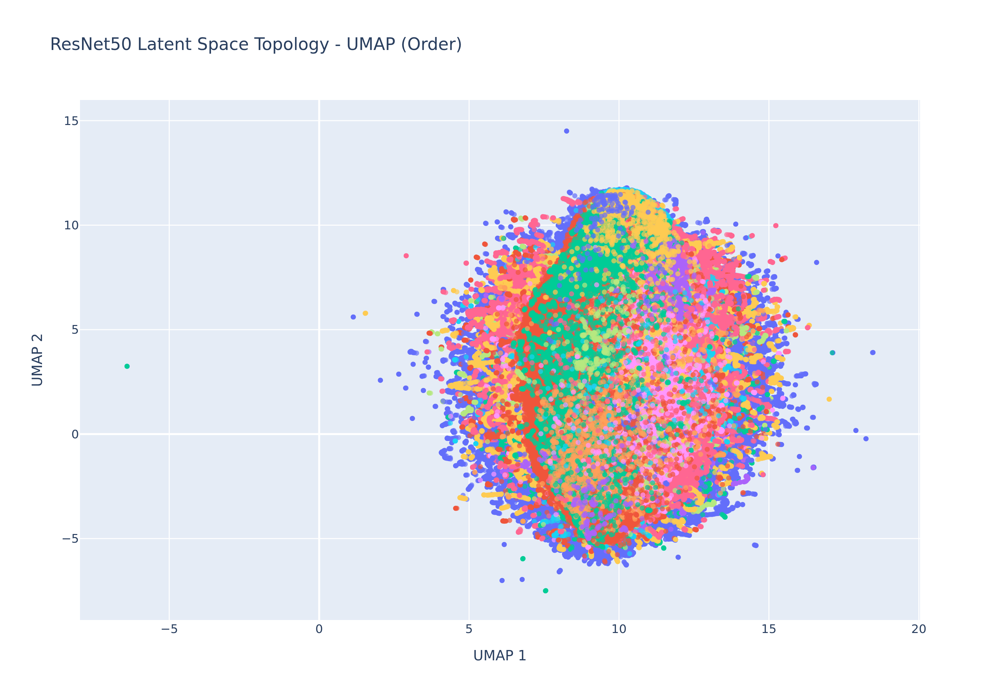

🧬 Mapeando linearmente 1706270 amostras para o nível 'Order'...
📊 Processando topologia UMAP para: ResNet50_finetuned...
🌐 HTML interativo salvo em disco (COM legenda): latent_plots/ICTV_latent_space_resnet50_finetuned_order.html
💾 Imagem estática salva (SEM legenda): latent_plots/ICTV_latent_space_resnet50_finetuned_order.png
Exibindo prévia estática colorida por Order...


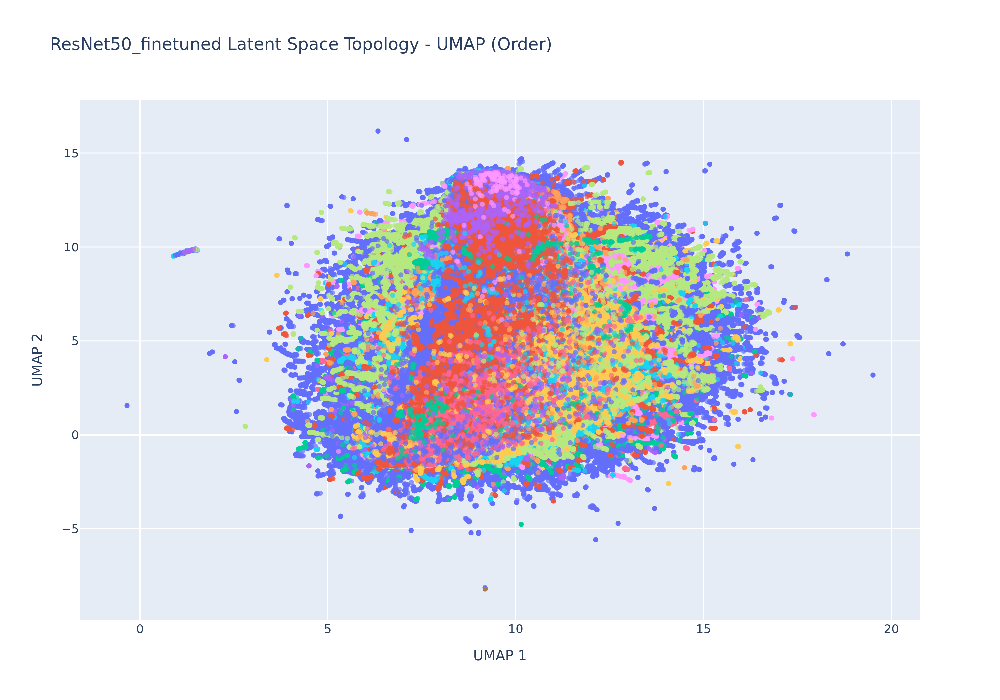

In [11]:
for model_dict in models:
    plot_latent_space(model_dict['umap'], model_dict['labels'], taxonomy_df, model_dict['model_name'],taxonomic_level="Order")
    

In [12]:
import torch
import torch.nn.functional as F  # <-- Importado para a normalização do cosseno
import numpy as np
import pandas as pd
import time
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

def evaluate_latent_clusters_pytorch_gpu(features, labels, taxonomy_df, model_name, taxonomic_level="order", sample_size=50000, batch_size=1000):
    """
    Calcula métricas de clusterização do espaço latente usando Distância por Cosseno, 
    retornando métricas GLOBAIS e métricas POR CLUSTER.
    """
    print(f"🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível '{taxonomic_level}' | Modelo: {model_name}...")
    start_time = time.time()
    
    # 1. Extrai o rótulo taxonômico desejado
    if taxonomic_level in taxonomy_df.columns:
        tax_labels = [taxonomy_df.loc[l, taxonomic_level] for l in labels]
    else:
        raise ValueError(f"❌ A coluna '{taxonomic_level}' não existe no taxonomy_df.")
        
    # Codifica os rótulos
    le = LabelEncoder()
    y_encoded = le.fit_transform(tax_labels)
    X = features

    # =====================================================================
    # MÉTRICA 1: Silhouette Score (Amostra na CPU) - Global e Por Cluster
    # =====================================================================
    rng = np.random.default_rng(42)
    n_samples = min(sample_size, len(X))
    idx_sample = rng.choice(len(X), n_samples, replace=False)
    X_sample = X[idx_sample]
    y_sample = y_encoded[idx_sample]
    
    val_counts = pd.Series(y_sample).value_counts()
    valid_classes = val_counts[val_counts > 1].index
    mask = np.isin(y_sample, valid_classes)
    
    # Dicionário para guardar a média do Silhouette por classe
    cluster_silhouette = {}
    
    if len(np.unique(y_sample[mask])) > 1:
        # Score Global usando métrica cosseno
        sil_score_global = silhouette_score(X_sample[mask], y_sample[mask], metric='cosine')
        
        # Score Individual (por amostra) usando métrica cosseno
        sample_sil_values = silhouette_samples(X_sample[mask], y_sample[mask], metric='cosine')
        
        # Calcula a média do Silhouette para cada cluster na amostra
        df_sil = pd.DataFrame({'class_encoded': y_sample[mask], 'sil_value': sample_sil_values})
        cluster_silhouette = df_sil.groupby('class_encoded')['sil_value'].mean().to_dict()
    else:
        sil_score_global = np.nan

    # =====================================================================
    # MÉTRICA 2: KNN Accuracy MASSIVO (GPU) - Global e Por Cluster
    # =====================================================================
    X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42,stratify=y_encoded)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    X_train_t = torch.tensor(X_train, device=device, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, device=device, dtype=torch.long)
    X_test_t = torch.tensor(X_test, device=device, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, device=device, dtype=torch.long)

    # L2 Normalize a base de treino para o cálculo do cosseno
    X_train_t = F.normalize(X_train_t, p=2, dim=1)

    total_preds = len(X_test_t)
    k = 5

    # Listas para guardar predições de todos os batches
    all_preds = []
    all_y_true = []

    for i in range(0, total_preds, batch_size):
        X_batch = X_test_t[i:i+batch_size]
        y_batch = y_test_t[i:i+batch_size]

        # L2 Normalize o batch de teste
        X_batch = F.normalize(X_batch, p=2, dim=1)

        # Distância por Cosseno: 1 - (A * B^T)
        cosine_sim = torch.mm(
            X_batch,
            X_train_t.T
        )
        
        topk_idx = torch.topk(
            cosine_sim,
            k,
            largest=True
        ).indices
        topk_labels = y_train_t[topk_idx]
        preds, _ = torch.mode(topk_labels, dim=1)

        # Move os resultados do batch para CPU e guarda na lista
        all_preds.append(preds.cpu())
        all_y_true.append(y_batch.cpu())

    # Concatena todos os tensores em um único array NumPy
    all_preds = torch.cat(all_preds).numpy()
    all_y_true = torch.cat(all_y_true).numpy()

    knn_acc_global = (all_preds == all_y_true).mean()
    
    # Limpa VRAM
    del X_train_t, y_train_t, X_test_t, y_test_t, cosine_sim
    torch.cuda.empty_cache()

    # =====================================================================
    # CONSTRUÇÃO DO DATAFRAME POR CLUSTER
    # =====================================================================
    # Cria DataFrame com todos os acertos e erros do KNN
    df_acc = pd.DataFrame({'y_true': all_y_true, 'y_pred': all_preds})
    df_acc['correct'] = df_acc['y_true'] == df_acc['y_pred']

    # Calcula Acurácia e Total de Amostras (no conjunto de teste) por Cluster
    df_cluster_metrics = df_acc.groupby('y_true').agg(
        Test_Samples=('y_true', 'count'),
        KNN_Accuracy=('correct', 'mean')
    ).reset_index()

    # Desfaz a codificação numérica para trazer os nomes originais em texto
    df_cluster_metrics['Taxon_Name'] = le.inverse_transform(df_cluster_metrics['y_true'])

    # Adiciona o Silhouette Score (mapeia pelo y_true)
    df_cluster_metrics['Silhouette_Score'] = df_cluster_metrics['y_true'].map(cluster_silhouette)

    # Adiciona as colunas de identificação para ajudar no cruzamento posterior
    df_cluster_metrics['Modelo'] = model_name
    df_cluster_metrics['Nivel_Taxonomico'] = taxonomic_level.capitalize()

    # Reorganiza e limpa as colunas
    df_cluster_metrics = df_cluster_metrics[['Modelo', 'Nivel_Taxonomico', 'Taxon_Name', 'Test_Samples', 'Silhouette_Score', 'KNN_Accuracy']]

    tempo_total = time.time() - start_time
    print(f"   • Silhouette Score Global: {sil_score_global:.4f}")
    print(f"   • KNN Accuracy Global: {knn_acc_global:.2%} (Processado em {tempo_total:.1f}s)")
    
    dict_global_metrics = {
        "Modelo": model_name,
        "Nível Taxonômico": taxonomic_level.capitalize(),
        "Silhouette Score": sil_score_global,
        "KNN Accuracy": knn_acc_global
    }
    
    return dict_global_metrics, df_cluster_metrics

In [13]:
import os
import pandas as pd

resultados_globais = []
dataframes_clusters = [] # Lista para guardar os dataframes detalhados

for model_dict in models:
    # Desempacotando os dois retornos
    global_mets, df_clusters = evaluate_latent_clusters_pytorch_gpu(
        features=model_dict['features'], 
        labels=model_dict['labels'], 
        taxonomy_df=taxonomy_df,  # Ou 'merged_df', dependendo de onde está sua coluna 'Genus'
        model_name=model_dict['model_name'], 
        taxonomic_level="Genus", # Mude para a sua coluna exata do DF
        sample_size=50000, 
        batch_size=2000
    )
    
    resultados_globais.append(global_mets)
    dataframes_clusters.append(df_clusters)

# 1. Tabela Global dos Modelos
df_global = pd.DataFrame(resultados_globais).sort_values(by="KNN Accuracy", ascending=False).reset_index(drop=True)
print("\n🏆 TABELA GLOBAL DE MODELOS 🏆")
display(df_global)

# 2. Tabela Detalhada por Cluster (Gênero)
# Junta o DataFrame de todos os modelos em um só e remove Gêneros que não caíram na amostra de Silhouette (opcional)
df_all_clusters = pd.concat(dataframes_clusters, ignore_index=True)

# Salva ambas no disco
os.makedirs("results_reports", exist_ok=True)
df_global.to_csv("results_reports/metricas_globais_genus.csv", index=False)
df_all_clusters.to_csv("results_reports/metricas_clusters_detalhados_genus.csv", index=False)
print(f"\n💾 Tabelas salvas com sucesso em 'results_reports/'.")

🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Genus' | Modelo: ConvNext finetuned...
   • Silhouette Score Global: -0.0728
   • KNN Accuracy Global: 80.88% (Processado em 195.8s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Genus' | Modelo: ConvNext from scratch...
   • Silhouette Score Global: -0.0781
   • KNN Accuracy Global: 79.09% (Processado em 202.5s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Genus' | Modelo: ConvNext transfer from genus...
   • Silhouette Score Global: -0.0739
   • KNN Accuracy Global: 80.76% (Processado em 201.3s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Genus' | Modelo: ResNet50...
   • Silhouette Score Global: -0.1813
   • KNN Accuracy Global: 67.98% (Processado em 209.4s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Genus' | Modelo: ResNet50_finetuned...
   • Silhouette Score Global: -0.1962
   • KNN Accuracy 

,Modelo,Nível Taxonômico,Silhouette Score,KNN Accuracy
0,ConvNext finetuned,Genus,-0.072848,0.808779
1,ConvNext transfer from genus,Genus,-0.073920,0.807601
2,ConvNext from scratch,Genus,-0.078075,0.790912
3,ResNet50_finetuned,Genus,-0.196194,0.697832
4,ResNet50,Genus,-0.181320,0.679843



💾 Tabelas salvas com sucesso em 'results_reports/'.


In [14]:
import os
import pandas as pd

resultados_globais = []
dataframes_clusters = [] # Lista para guardar os dataframes detalhados

for model_dict in models:
    # Desempacotando os dois retornos
    global_mets, df_clusters = evaluate_latent_clusters_pytorch_gpu(
        features=model_dict['features'], 
        labels=model_dict['labels'], 
        taxonomy_df=taxonomy_df,  # Ou 'merged_df', dependendo de onde está sua coluna 'Genus'
        model_name=model_dict['model_name'], 
        taxonomic_level="Order", # Mude para a sua coluna exata do DF
        sample_size=50000, 
        batch_size=1000
    )
    
    resultados_globais.append(global_mets)
    dataframes_clusters.append(df_clusters)

# 1. Tabela Global dos Modelos
df_global = pd.DataFrame(resultados_globais).sort_values(by="KNN Accuracy", ascending=False).reset_index(drop=True)
print("\n🏆 TABELA GLOBAL DE MODELOS 🏆")
display(df_global)

# 2. Tabela Detalhada por Cluster (Gênero)
# Junta o DataFrame de todos os modelos em um só e remove Gêneros que não caíram na amostra de Silhouette (opcional)
df_all_clusters = pd.concat(dataframes_clusters, ignore_index=True)

# Salva ambas no disco
os.makedirs("results_reports", exist_ok=True)
df_global.to_csv("results_reports/metricas_globais_order.csv", index=False)
df_all_clusters.to_csv("results_reports/metricas_clusters_detalhados_order.csv", index=False)
print(f"\n💾 Tabelas salvas com sucesso em 'results_reports/'.")

🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Order' | Modelo: ConvNext finetuned...
   • Silhouette Score Global: -0.0448
   • KNN Accuracy Global: 86.49% (Processado em 186.7s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Order' | Modelo: ConvNext from scratch...
   • Silhouette Score Global: -0.0459
   • KNN Accuracy Global: 84.47% (Processado em 190.6s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Order' | Modelo: ConvNext transfer from genus...
   • Silhouette Score Global: -0.0483
   • KNN Accuracy Global: 86.50% (Processado em 192.7s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Order' | Modelo: ResNet50...
   • Silhouette Score Global: -0.0855
   • KNN Accuracy Global: 73.79% (Processado em 198.6s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'Order' | Modelo: ResNet50_finetuned...
   • Silhouette Score Global: -0.0936
   • KNN Accuracy 

,Modelo,Nível Taxonômico,Silhouette Score,KNN Accuracy
0,ConvNext transfer from genus,Order,-0.048264,0.865007
1,ConvNext finetuned,Order,-0.044751,0.864925
2,ConvNext from scratch,Order,-0.045936,0.844676
3,ResNet50_finetuned,Order,-0.093595,0.765348
4,ResNet50,Order,-0.085477,0.737905



💾 Tabelas salvas com sucesso em 'results_reports/'.


In [15]:
import os
import pandas as pd

resultados_globais = []
dataframes_clusters = [] # Lista para guardar os dataframes detalhados

for model_dict in models:
    # Desempacotando os dois retornos
    global_mets, df_clusters = evaluate_latent_clusters_pytorch_gpu(
        features=model_dict['features'], 
        labels=model_dict['labels'], 
        taxonomy_df=taxonomy_df,  # Ou 'merged_df', dependendo de onde está sua coluna 'Genus'
        model_name=model_dict['model_name'], 
        taxonomic_level="species", # Mude para a sua coluna exata do DF
        sample_size=50000, 
        batch_size=1000
    )
    
    resultados_globais.append(global_mets)
    dataframes_clusters.append(df_clusters)

# 1. Tabela Global dos Modelos
df_global = pd.DataFrame(resultados_globais).sort_values(by="KNN Accuracy", ascending=False).reset_index(drop=True)
print("\n🏆 TABELA GLOBAL DE MODELOS 🏆")
display(df_global)

# 2. Tabela Detalhada por Cluster (Gênero)
# Junta o DataFrame de todos os modelos em um só e remove Gêneros que não caíram na amostra de Silhouette (opcional)
df_all_clusters = pd.concat(dataframes_clusters, ignore_index=True)

# Salva ambas no disco
os.makedirs("results_reports", exist_ok=True)
df_global.to_csv("results_reports/metricas_globais_species.csv", index=False)
df_all_clusters.to_csv("results_reports/metricas_clusters_detalhados_species.csv", index=False)
print(f"\n💾 Tabelas salvas com sucesso em 'results_reports/'.")

🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'species' | Modelo: ConvNext finetuned...
   • Silhouette Score Global: -0.0376
   • KNN Accuracy Global: 62.85% (Processado em 166.2s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'species' | Modelo: ConvNext from scratch...
   • Silhouette Score Global: -0.0495
   • KNN Accuracy Global: 62.71% (Processado em 191.6s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'species' | Modelo: ConvNext transfer from genus...
   • Silhouette Score Global: -0.0366
   • KNN Accuracy Global: 63.01% (Processado em 179.3s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'species' | Modelo: ResNet50...
   • Silhouette Score Global: -0.1882
   • KNN Accuracy Global: 51.96% (Processado em 195.6s)
🚀 [PyTorch GPU] Calculando métricas (Globais e Por Cluster) para o nível 'species' | Modelo: ResNet50_finetuned...
   • Silhouette Score Global: -0.1887
   • KNN

,Modelo,Nível Taxonômico,Silhouette Score,KNN Accuracy
0,ConvNext transfer from genus,Species,-0.036551,0.630129
1,ConvNext finetuned,Species,-0.037639,0.628488
2,ConvNext from scratch,Species,-0.049464,0.627067
3,ResNet50_finetuned,Species,-0.188691,0.534918
4,ResNet50,Species,-0.188201,0.519648



💾 Tabelas salvas com sucesso em 'results_reports/'.


In [16]:
df_species = pd.read_csv("results_reports/metricas_clusters_detalhados_species.csv")
df_species.tail()

,Modelo,Nivel_Taxonomico,Taxon_Name,Test_Samples,Silhouette_Score,KNN_Accuracy
68360,ResNet50_finetuned,Species,uncultured Caudovirales phage,23,NaN,0.260870
68361,ResNet50_finetuned,Species,uncultured densovirus,20,-0.310021,0.600000
68362,ResNet50_finetuned,Species,uncultured phage WW-nAnB,25,NaN,1.000000
68363,ResNet50_finetuned,Species,uncultured virus,24,0.009346,0.916667
68364,ResNet50_finetuned,Species,unidentified entomopoxvirus,27,0.633722,0.925926


In [18]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

df_species = pd.read_csv(
    "results_reports/metricas_clusters_detalhados_species.csv"
)

df_genus = pd.read_csv(
    "results_reports/metricas_clusters_detalhados_genus.csv"
)

df_order = pd.read_csv(
    "results_reports/metricas_clusters_detalhados_order.csv"
)

# Standardize level names
df_species["Nivel_Taxonomico"] = "Species"
df_genus["Nivel_Taxonomico"] = "Genus"
df_order["Nivel_Taxonomico"] = "Order"

In [19]:
taxonomy_map = taxonomy_df[
    ["species", "Genus", "Order"]
].drop_duplicates()

taxonomy_map = taxonomy_map.dropna(
    subset=["species", "Genus", "Order"]
)
for col in ["species", "Genus", "Order"]:
    taxonomy_map[col] = (
        taxonomy_map[col]
        .astype(str)
        .str.strip()
    )

In [27]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd
import numpy as np


def calculate_parent_child_correlation(
    child_df,
    parent_df,
    taxonomy_df,
    child_tax_col,
    parent_tax_col,
    child_level,
    parent_level
):

    results = []

    models = sorted(
        set(child_df["Modelo"])
        & set(parent_df["Modelo"])
    )

    for model in models:

        # =====================================================
        # Child metrics
        # =====================================================

        child = child_df[
            child_df["Modelo"] == model
        ].copy()

        child = child[
            [
                "Taxon_Name",
                "Test_Samples",
                "Silhouette_Score",
                "KNN_Accuracy"
            ]
        ]

        # =====================================================
        # Parent metrics
        # =====================================================

        parent = parent_df[
            parent_df["Modelo"] == model
        ].copy()

        parent = parent[
            [
                "Taxon_Name",
                "Test_Samples",
                "Silhouette_Score",
                "KNN_Accuracy"
            ]
        ].rename(
            columns={
                "Taxon_Name": "Parent_Taxon",
                "Test_Samples": "Parent_Test_Samples",
                "Silhouette_Score": "Parent_Silhouette",
                "KNN_Accuracy": "Parent_KNN"
            }
        )

        # =====================================================
        # Child -> parent mapping
        # =====================================================

        mapping = taxonomy_df[
            [child_tax_col, parent_tax_col]
        ].drop_duplicates()

        mapping = mapping.rename(
            columns={
                child_tax_col: "Taxon_Name",
                parent_tax_col: "Parent_Taxon"
            }
        )

        merged = child.merge(
            mapping,
            on="Taxon_Name",
            how="inner"
        )

        merged = merged.merge(
            parent,
            on="Parent_Taxon",
            how="inner"
        )

        # =====================================================
        # KNN analysis
        # Independent from Silhouette availability
        # =====================================================

        knn_data = merged.dropna(
            subset=[
                "KNN_Accuracy",
                "Parent_KNN"
            ]
        )

        knn_summary = (
            knn_data
            .groupby("Parent_Taxon")
            .agg(
                Child_KNN=(
                    "KNN_Accuracy",
                    "mean"
                ),
                Parent_KNN=(
                    "Parent_KNN",
                    "first"
                ),
                N_Children_KNN=(
                    "Taxon_Name",
                    "nunique"
                )
            )
            .reset_index()
        )

        # =====================================================
        # Silhouette analysis
        # Independent from KNN availability
        # =====================================================

        sil_data = merged.dropna(
            subset=[
                "Silhouette_Score",
                "Parent_Silhouette"
            ]
        )

        sil_summary = (
            sil_data
            .groupby("Parent_Taxon")
            .agg(
                Child_Silhouette=(
                    "Silhouette_Score",
                    "mean"
                ),
                Parent_Silhouette=(
                    "Parent_Silhouette",
                    "first"
                ),
                N_Children_Silhouette=(
                    "Taxon_Name",
                    "nunique"
                )
            )
            .reset_index()
        )

        # =====================================================
        # Correlations
        # =====================================================

        if len(knn_summary) >= 3:

            r_knn, p_knn = pearsonr(
                knn_summary["Child_KNN"],
                knn_summary["Parent_KNN"]
            )

            rho_knn, p_rho_knn = spearmanr(
                knn_summary["Child_KNN"],
                knn_summary["Parent_KNN"]
            )

        else:

            r_knn = p_knn = np.nan
            rho_knn = p_rho_knn = np.nan

        if len(sil_summary) >= 3:

            r_sil, p_sil = pearsonr(
                sil_summary["Child_Silhouette"],
                sil_summary["Parent_Silhouette"]
            )

            rho_sil, p_rho_sil = spearmanr(
                sil_summary["Child_Silhouette"],
                sil_summary["Parent_Silhouette"]
            )

        else:

            r_sil = p_sil = np.nan
            rho_sil = p_rho_sil = np.nan

        # =====================================================
        # Results
        # =====================================================

        results.append({

            "Modelo": model,

            "Child_Level": child_level,
            "Parent_Level": parent_level,

            "N_Parents_KNN":
                len(knn_summary),

            "N_Parents_Silhouette":
                len(sil_summary),

            "Pearson_KNN":
                r_knn,

            "Pearson_KNN_p":
                p_knn,

            "Spearman_KNN":
                rho_knn,

            "Spearman_KNN_p":
                p_rho_knn,

            "Pearson_Silhouette":
                r_sil,

            "Pearson_Silhouette_p":
                p_sil,

            "Spearman_Silhouette":
                rho_sil,

            "Spearman_Silhouette_p":
                p_rho_sil
        })

    return pd.DataFrame(results)

In [28]:
species_genus_results = calculate_parent_child_correlation(
    child_df=df_species,
    parent_df=df_genus,
    taxonomy_df=taxonomy_map,
    child_tax_col="species",
    parent_tax_col="Genus",
    child_level="Species",
    parent_level="Genus"
)

display(
    species_genus_results.sort_values(
        "Spearman_KNN",
        ascending=False
    )
)

,Modelo,Child_Level,Parent_Level,N_Parents_KNN,N_Parents_Silhouette,Pearson_KNN,Pearson_KNN_p,Spearman_KNN,Spearman_KNN_p,Pearson_Silhouette,Pearson_Silhouette_p,Spearman_Silhouette,Spearman_Silhouette_p
3,ResNet50,Species,Genus,2321,2166,0.925108,0.0,0.882810,0.0,0.877274,0.0,0.807793,0.0
4,ResNet50_finetuned,Species,Genus,2321,2160,0.920810,0.0,0.874269,0.0,0.918080,0.0,0.867389,0.0
1,ConvNext from scratch,Species,Genus,2321,2155,0.885775,0.0,0.864878,0.0,0.912171,0.0,0.809690,0.0
0,ConvNext finetuned,Species,Genus,2321,2159,0.864255,0.0,0.854120,0.0,0.870097,0.0,0.821846,0.0
2,ConvNext transfer from genus,Species,Genus,2321,2154,0.865560,0.0,0.849636,0.0,0.899476,0.0,0.805720,0.0


In [30]:
genus_order_results = calculate_parent_child_correlation(
    child_df=df_genus,
    parent_df=df_order,
    taxonomy_df=taxonomy_map,
    child_tax_col="Genus",
    parent_tax_col="Order",
    child_level="Genus",
    parent_level="Order"
)

display(
    genus_order_results.sort_values(
        "Spearman_KNN",
        ascending=False
    )
)

,Modelo,Child_Level,Parent_Level,N_Parents_KNN,N_Parents_Silhouette,Pearson_KNN,Pearson_KNN_p,Spearman_KNN,Spearman_KNN_p,Pearson_Silhouette,Pearson_Silhouette_p,Spearman_Silhouette,Spearman_Silhouette_p
1,ConvNext from scratch,Genus,Order,74,74,0.919888,5.469285e-31,0.943851,2.313544e-36,0.565548,1.518721e-07,0.391129,0.000570
0,ConvNext finetuned,Genus,Order,74,73,0.913540,7.610185e-30,0.940987,1.319716e-35,0.497128,7.676536e-06,0.376681,0.001021
2,ConvNext transfer from genus,Genus,Order,74,73,0.900400,9.812242e-28,0.937641,9.059322e-35,0.498064,7.334001e-06,0.332192,0.004088
3,ResNet50,Genus,Order,74,73,0.940225,2.065996e-35,0.935192,3.473203e-34,0.551035,4.380027e-07,0.421480,0.000204
4,ResNet50_finetuned,Genus,Order,74,73,0.912751,1.040589e-29,0.917842,1.307756e-30,0.389444,6.604509e-04,0.338887,0.003359


In [31]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

def plot_parent_child(
    child_df,
    parent_df,
    taxonomy_df,
    child_tax_col,
    parent_tax_col,
    model,
    metric="KNN_Accuracy"
):

    child = child_df[
        child_df["Modelo"] == model
    ].copy()

    parent = parent_df[
        parent_df["Modelo"] == model
    ].copy()

    parent = parent[
        ["Taxon_Name", metric]
    ].rename(columns={
        "Taxon_Name": "Parent_Taxon",
        metric: "Parent_Metric"
    })

    mapping = taxonomy_df[
        [child_tax_col, parent_tax_col]
    ].drop_duplicates()

    mapping = mapping.rename(columns={
        child_tax_col: "Taxon_Name",
        parent_tax_col: "Parent_Taxon"
    })

    merged = child.merge(
        mapping,
        on="Taxon_Name",
        how="inner"
    )

    merged = merged.merge(
        parent,
        on="Parent_Taxon",
        how="inner"
    )
    merged = merged.dropna(
        subset=[metric, "Parent_Metric"]
    )
    
    # Mean child performance per parent
    summary = (
        merged
        .groupby("Parent_Taxon")
        .agg(
            Child_Metric=(metric, "mean"),
            Parent_Metric=("Parent_Metric", "first"),
            N_Children=("Taxon_Name", "nunique")
        )
        .reset_index()
    )

    rho, p = spearmanr(
        summary["Child_Metric"],
        summary["Parent_Metric"]
    )

    plt.figure(figsize=(7, 6))

    plt.scatter(
        summary["Parent_Metric"],
        summary["Child_Metric"],
        alpha=0.55,
        s=30
    )

    plt.xlabel(
        f"{parent_df['Nivel_Taxonomico'].iloc[0]} {metric}"
    )

    plt.ylabel(
        f"Mean {child_df['Nivel_Taxonomico'].iloc[0]} {metric}"
    )

    plt.title(
        f"{model}: "
        f"{child_df['Nivel_Taxonomico'].iloc[0]} → "
        f"{parent_df['Nivel_Taxonomico'].iloc[0]}"
    )

    plt.text(
        0.05,
        0.95,
        f"Spearman ρ = {rho:.3f}\np = {p:.2e}",
        transform=plt.gca().transAxes,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.8
        )
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    return summary

ConvNext finetuned


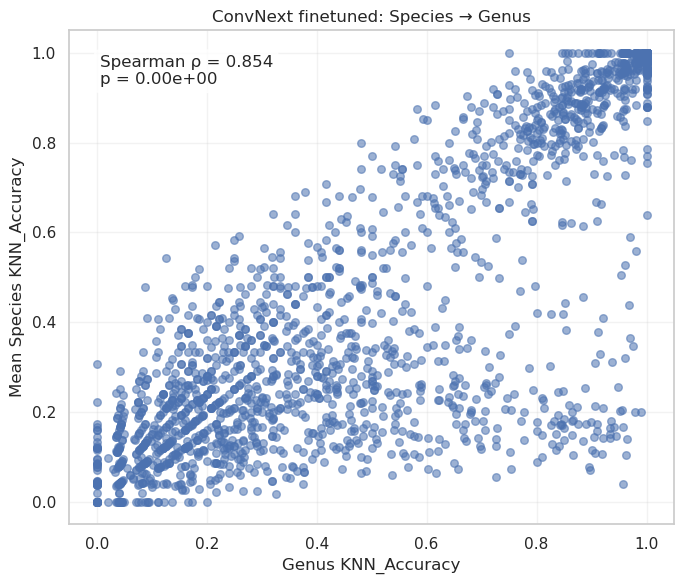

           Parent_Taxon  Child_Metric  Parent_Metric  N_Children
0             Aalivirus      1.000000       0.863636           1
1           Aarhusvirus      0.377514       0.912621           4
2            Abaiavirus      0.500000       0.291667           1
3     Abbeymikolonvirus      0.500000       0.384615           1
4          Aberdnavirus      1.000000       0.962963           1
...                 ...           ...            ...         ...
2316        Zindervirus      0.260556       0.650000           3
2317         Zitchvirus      0.111648       0.297297           3
2318          Zukovirus      0.125000       0.240000           2
2319          Zurivirus      0.208333       0.250000           1
2320          Zybavirus      1.000000       1.000000           1

[2321 rows x 4 columns]
ConvNext from scratch


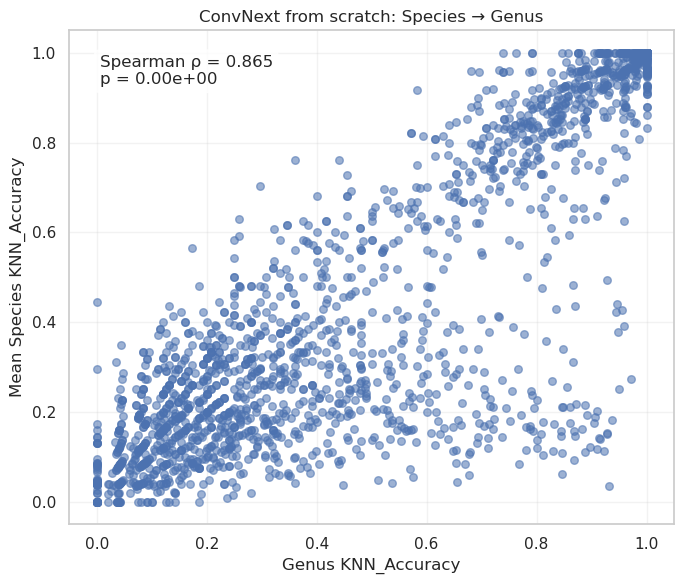

           Parent_Taxon  Child_Metric  Parent_Metric  N_Children
0             Aalivirus      0.863636       0.818182           1
1           Aarhusvirus      0.430217       0.834951           4
2            Abaiavirus      0.583333       0.333333           1
3     Abbeymikolonvirus      0.461538       0.307692           1
4          Aberdnavirus      1.000000       0.925926           1
...                 ...           ...            ...         ...
2316        Zindervirus      0.211111       0.575000           3
2317         Zitchvirus      0.138486       0.283784           3
2318          Zukovirus      0.198052       0.120000           2
2319          Zurivirus      0.083333       0.166667           1
2320          Zybavirus      0.958333       1.000000           1

[2321 rows x 4 columns]
ConvNext transfer from genus


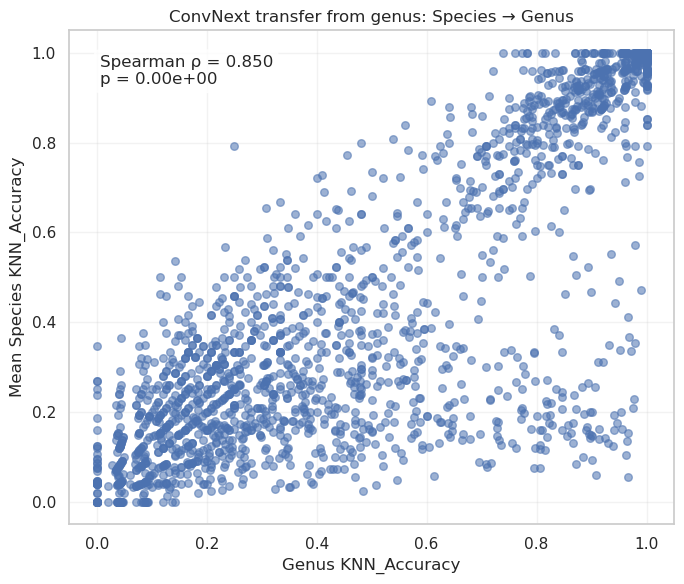

           Parent_Taxon  Child_Metric  Parent_Metric  N_Children
0             Aalivirus      0.954545       0.818182           1
1           Aarhusvirus      0.349409       0.932039           4
2            Abaiavirus      0.458333       0.250000           1
3     Abbeymikolonvirus      0.461538       0.384615           1
4          Aberdnavirus      1.000000       1.000000           1
...                 ...           ...            ...         ...
2316        Zindervirus      0.176667       0.587500           3
2317         Zitchvirus      0.233494       0.324324           3
2318          Zukovirus      0.152597       0.220000           2
2319          Zurivirus      0.125000       0.083333           1
2320          Zybavirus      1.000000       1.000000           1

[2321 rows x 4 columns]
ResNet50


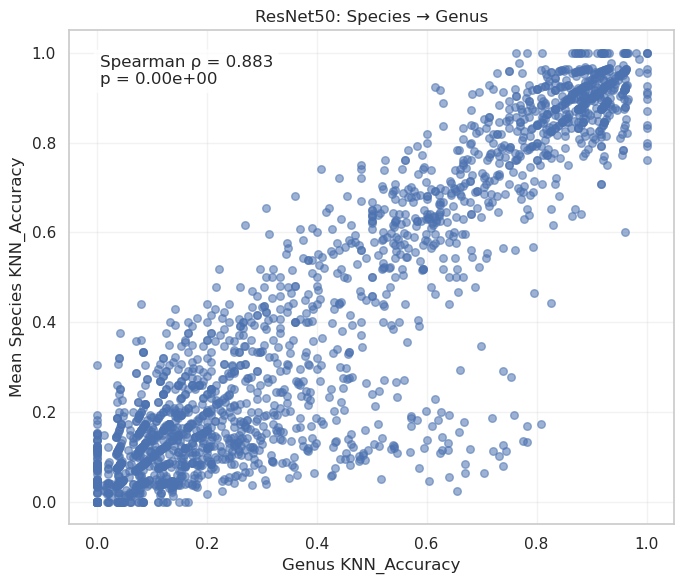

           Parent_Taxon  Child_Metric  Parent_Metric  N_Children
0             Aalivirus      0.727273       0.681818           1
1           Aarhusvirus      0.380983       0.446602           4
2            Abaiavirus      0.416667       0.291667           1
3     Abbeymikolonvirus      0.230769       0.153846           1
4          Aberdnavirus      0.814815       0.851852           1
...                 ...           ...            ...         ...
2316        Zindervirus      0.227222       0.387500           3
2317         Zitchvirus      0.140633       0.243243           3
2318          Zukovirus      0.063312       0.120000           2
2319          Zurivirus      0.041667       0.000000           1
2320          Zybavirus      0.833333       0.750000           1

[2321 rows x 4 columns]
ResNet50_finetuned


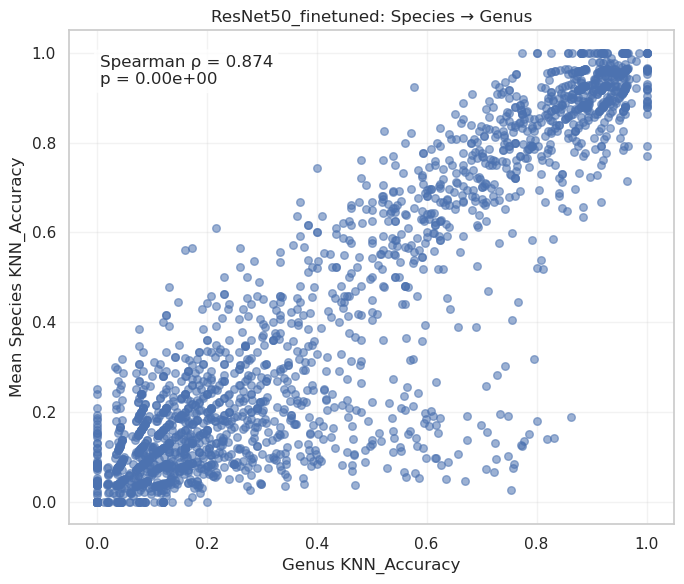

           Parent_Taxon  Child_Metric  Parent_Metric  N_Children
0             Aalivirus      0.909091       0.681818           1
1           Aarhusvirus      0.364035       0.563107           4
2            Abaiavirus      0.250000       0.083333           1
3     Abbeymikolonvirus      0.307692       0.269231           1
4          Aberdnavirus      0.925926       0.962963           1
...                 ...           ...            ...         ...
2316        Zindervirus      0.098889       0.387500           3
2317         Zitchvirus      0.099302       0.162162           3
2318          Zukovirus      0.040584       0.120000           2
2319          Zurivirus      0.083333       0.000000           1
2320          Zybavirus      0.916667       0.916667           1

[2321 rows x 4 columns]


In [37]:
for model_dict in models:
    print(model_dict['model_name'])
    summary = plot_parent_child(
        df_species,
        df_genus,
        taxonomy_map,
        "species",
        "Genus",
        model_dict['model_name'],
        metric="KNN_Accuracy"
    )
    print(summary)

In [38]:
check = (
    taxonomy_map
    .groupby("species")["Genus"]
    .nunique()
)

print(
    "Species with multiple genera:",
    (check > 1).sum()
)

check = (
    taxonomy_map
    .groupby("Genus")["Order"]
    .nunique()
)

print(
    "Genera with multiple orders:",
    (check > 1).sum()
)

Species with multiple genera: 0
Genera with multiple orders: 0
